In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cv2

In [2]:
# Calibración usando los puntos 3D M con sus proyecciones w

def calibra(M,w):

  n = M.shape[1]

  for i in range(n):
    X   = M[0,i]
    Y   = M[1,i]
    Z   = M[2,i]
    u   = w[0,i]
    v   = w[1,i]
    x1  = np.array([X,Y,Z,1,0,0,0,0,-u*X,-u*Y,-u*Z])
    x2  = np.array([0,0,0,0,X,Y,Z,1,-v*X,-v*Y,-v*Z])
    XXi = np.vstack([x1,x2])
    bbi = w[0:2,i].reshape(2,1)
    if i==0:
      XX = XXi
      bb = bbi
    else:
      XX = np.vstack([XX,XXi])
      bb = np.vstack([bb,bbi])
  a = np.linalg.lstsq(XX, bb, rcond=None)[0]


  # Matriz de proyección estimada
  P  = np.array([
          [a[0][0], a[1][0], a[2][0], a[3][0]],
          [a[4][0], a[5][0], a[6][0], a[7][0]],
          [a[8][0], a[9][0], a[10][0], 1]])
  return P



In [19]:
!wget https://www.dropbox.com/scl/fi/9ysvgfksbw7x3bvfpsb8k/mesa.png?rlkey=hw0tfx9akefhnqqcvgnl97ei4
!mv mesa.png?rlkey=hw0tfx9akefhnqqcvgnl97ei4 mesa.png

--2026-06-23 17:19:00--  https://www.dropbox.com/scl/fi/9ysvgfksbw7x3bvfpsb8k/mesa.png?rlkey=hw0tfx9akefhnqqcvgnl97ei4
Resolving www.dropbox.com (www.dropbox.com)... 162.125.1.18, 2620:100:6016:18::a27d:112
Connecting to www.dropbox.com (www.dropbox.com)|162.125.1.18|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://uc862ad59dc124131cb3c23d7f05.dl.dropboxusercontent.com/cd/0/inline/DC8ToG-lBMjZsdWddozzczMsHhFj0N_1fqYQQGbZV1cE22tHzkS3TgehcJOJbW-4r-Y6MXnXuiC5LIhZMx6I02PXVG1j4pAvbx_SctT1jCP6woNZH2ycQzZG1TPMOXTUPRM/file# [following]
--2026-06-23 17:19:00--  https://uc862ad59dc124131cb3c23d7f05.dl.dropboxusercontent.com/cd/0/inline/DC8ToG-lBMjZsdWddozzczMsHhFj0N_1fqYQQGbZV1cE22tHzkS3TgehcJOJbW-4r-Y6MXnXuiC5LIhZMx6I02PXVG1j4pAvbx_SctT1jCP6woNZH2ycQzZG1TPMOXTUPRM/file
Resolving uc862ad59dc124131cb3c23d7f05.dl.dropboxusercontent.com (uc862ad59dc124131cb3c23d7f05.dl.dropboxusercontent.com)... 162.125.1.15, 2620:100:6016:15::a27d:10f
Connecting to uc862ad59dc

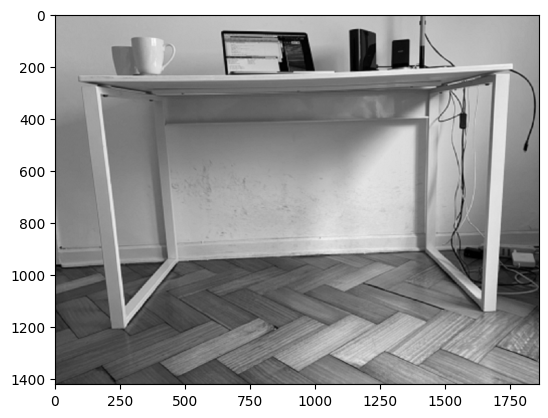

In [20]:
I = cv2.imread('mesa.png',0)
plt.imshow(I,cmap='gray')
plt.show()

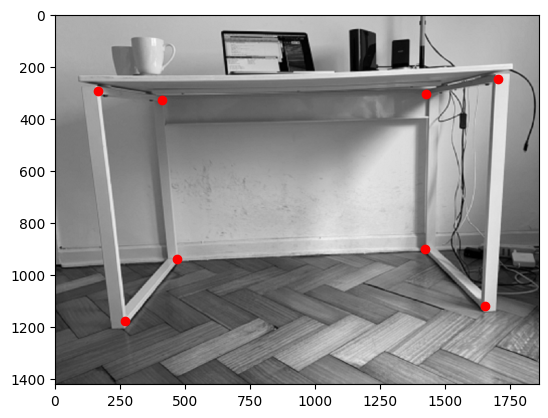

In [21]:
u = np.array([  268,  166, 412, 470, 1654, 1704, 1426, 1420])
v = np.array([ 1178,  294, 328, 940, 1118,  246,  304,  900])
o = np.ones((1,len(u)))
w = np.vstack([u,v,o])

plt.imshow(I,cmap='gray')
plt.scatter(u,v,c='red')
plt.show()

In [22]:
a =  800 # fondo de la mesa en milimetros
h =  900 # alto de la mesa
c = 1250 # ancho de la mesa
p0 = np.array([   a,    0,    0, 1]).reshape(4,1)
p1 = np.array([   a,    0,    h, 1]).reshape(4,1)
p2 = np.array([   0,    0,    h, 1]).reshape(4,1)
p3 = np.array([   0,    0,    0, 1]).reshape(4,1)
p4 = np.array([   a,    c,    0, 1]).reshape(4,1)
p5 = np.array([   a,    c,    h, 1]).reshape(4,1)
p6 = np.array([   0,    c,    h, 1]).reshape(4,1)
p7 = np.array([   0,    c,    0, 1]).reshape(4,1)

M = np.hstack([p0,p1,p2,p3,p4,p5,p6,p7])
M

array([[ 800,  800,    0,    0,  800,  800,    0,    0],
       [   0,    0,    0,    0, 1250, 1250, 1250, 1250],
       [   0,  900,  900,    0,    0,  900,  900,    0],
       [   1,    1,    1,    1,    1,    1,    1,    1]])

In [23]:
P = calibra(M,w)
print(P)

[[-3.53835580e-01  7.80388436e-01 -9.30689067e-02  4.68294197e+02]
 [-1.64678172e-01 -1.72248873e-02 -6.97780265e-01  9.37657307e+02]
 [-3.96708273e-04  1.45711356e-05 -7.44849298e-05  1.00000000e+00]]


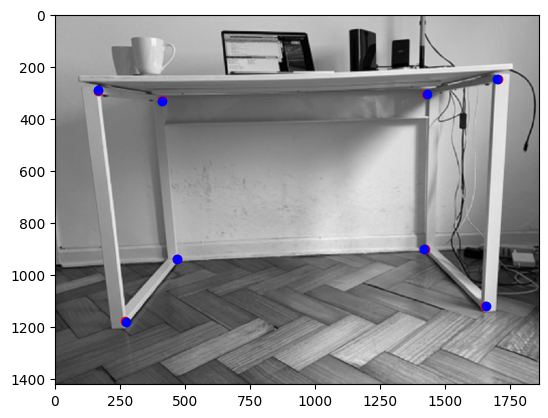

In [24]:
plt.imshow(I,cmap='gray')
plt.scatter(w[0,:],w[1,:],c='red')

ws = np.dot(P,M)
ws = ws/ws[-1]
plt.scatter(ws[0,:],ws[1,:],c='blue')

plt.show()

In [25]:
np.fix(ws)
w =  w = np.vstack([u,v])

print('Puntos medidos:')
print(w[0:2,:])
print('Puntos estimados:')
print(np.fix(ws[0:2,:]))


Puntos medidos:
[[ 268  166  412  470 1654 1704 1426 1420]
 [1178  294  328  940 1118  246  304  900]]
Puntos estimados:
[[ 271.  164.  412.  468. 1656. 1699. 1429. 1417.]
 [1180.  289.  331.  937. 1119.  246.  302.  899.]]


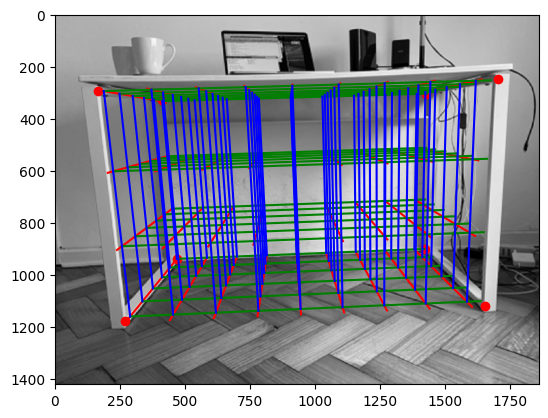

In [26]:
plt.imshow(I,cmap='gray')
plt.scatter(w[0,:],w[1,:],c='red')

for Z in range(0,h+1,300):
  for Y in range(0,c,150):
    q0 = np.array([   0,    Y,    Z, 1]).reshape(4,1)
    q1 = np.array([   a,    Y,    Z, 1]).reshape(4,1)
    Mq = np.hstack([q0,q1])
    wq = np.dot(P,Mq)
    wq = wq/wq[-1]
    plt.plot(wq[0,:],wq[1,:],color='r')

for Z in range(0,h+1,300):
  for X in range(0,a,150):
    q0 = np.array([   X,    0,    Z, 1]).reshape(4,1)
    q1 = np.array([   X,    c,    Z, 1]).reshape(4,1)
    Mq = np.hstack([q0,q1])
    wq = np.dot(P,Mq)
    wq = wq/wq[-1]
    plt.plot(wq[0,:],wq[1,:],color='g')

for Y in range(0,c,150):
  for X in range(0,a,150):
    q0 = np.array([   X,    Y,    0, 1]).reshape(4,1)
    q1 = np.array([   X,    Y,    h, 1]).reshape(4,1)
    Mq = np.hstack([q0,q1])
    wq = np.dot(P,Mq)
    wq = wq/wq[-1]
    plt.plot(wq[0,:],wq[1,:],color='b')

plt.show()